<a href="https://colab.research.google.com/github/nkoushani18/End-to-End-ASR-and-TTS-Pipeline-for-Stuttered-Disfluent-Bengali-Speech/blob/main/submission_notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# From Voice to Text and Back: ASR and TTS on Stuttered Bengali Speech
**21CSE453T Speech Recognition · Activity Unit-3**

**Objective.** Take an audio file that contains a stammer / stutter (a temporary disruption of the normal vocal pattern)
and follow it through the complete chain

`Speech → Feature Extraction → Log-Mel Spectrum → ASR → CTC → Text → TTS → Speech`

| Required item (faculty sheet) | Where in this notebook |
|---|---|
| Python / Colab notebook | this file (runs locally and on Colab) |
| Waveform and log-Mel spectrogram | sections 1 and 3 |
| ASR architecture diagram | section 4 |
| CTC explanation | section 6 |
| WER calculations | section 8 |
| ASR comparison table | section 9 |
| TTS output | section 10 |
| 2-page mini-report and 3-minute demonstration | produced from this notebook's results (`results.json`, `assets/`) |

**Data.** One of my own recordings of stuttered Bengali speech (a WhatsApp voice note). The sentence I meant to say is
*আমি বুঝতে পারছি না* ("I don't understand"); I confirmed this reference by listening to the clip.
The public Boli stuttering dataset has no Bengali audio, so it is not used here.

## 0. Setup

In [ ]:
import sys, subprocess
if "google.colab" in sys.modules:                       # on Colab install what is missing; locally this is skipped
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "jiwer", "librosa", "soundfile", "transformers"], check=False)

import os, re, json, time, unicodedata, warnings
os.environ.setdefault("USE_TF", "0")                    # this notebook only needs PyTorch
from pathlib import Path
import numpy as np, pandas as pd
import librosa, soundfile as sf, jiwer, torch
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
from matplotlib.patches import FancyBboxPatch
from scipy.signal import medfilt, find_peaks
from IPython.display import Audio, display
warnings.filterwarnings("ignore")
import transformers; transformers.logging.set_verbosity_error()     # hide harmless library warnings (not errors)

SR = 16000                                              # all models in this notebook expect 16 kHz mono
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
C = dict(floor="#5c1a12", rice="#f6eedd", vermilion="#e8432a", marigold="#f59e1b",
         turmeric="#f7cf2a", magenta="#c8246b", indigo="#2c3a92", leaf="#2f8f4e")
BN_FONT = next((f.name for f in fm.fontManager.ttflist if f.name in
                ("Nirmala UI", "Noto Sans Bengali", "Noto Serif Bengali", "Vrinda", "Lohit Bengali", "Kalpurush")), None)
def bn(size=9):                                          # font for single Bengali letters in plots
    return fm.FontProperties(family=BN_FONT, size=size) if BN_FONT else None
print(f"device: {DEVICE} | torch {torch.__version__} | Bengali plot font: {BN_FONT}")

device: cpu | torch 2.1.0+cpu | Bengali plot font: Nirmala UI


In [ ]:
# ---- configuration: the stuttered clip and what the speaker actually said ------------------------------------
AUDIO_FILE = "WhatsApp Ptt 2026-10-14 at 10.25.02 AM.ogg"
REFERENCE  = "আমি বুঝতে পারছি না"                          # verified by the speaker (listened to the clip)
OUT = Path("assets"); OUT.mkdir(exist_ok=True)

AUDIO_PATH = next((d / AUDIO_FILE for d in (Path("../dataset"), Path("dataset"), Path(".")) if (d / AUDIO_FILE).exists()), None)
if AUDIO_PATH is None and "google.colab" in sys.modules:
    from google.colab import files                      # Colab: upload the clip when asked
    AUDIO_PATH = Path(next(iter(files.upload())))
assert AUDIO_PATH is not None, f"Put '{AUDIO_FILE}' in ../dataset or next to this notebook"
print("audio:", AUDIO_PATH, "\nreference:", REFERENCE)

audio: ..\dataset\WhatsApp Ptt 2026-10-14 at 10.25.02 AM.ogg 
reference: আমি বুঝতে পারছি না


### Pipeline overview
Each box is one stage of the activity. The notebook follows the same order; the two yellow stages are where the stutter
becomes visible in the model output.

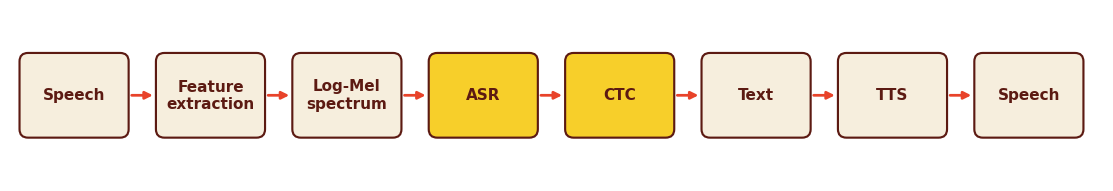

In [ ]:
labels = ["Speech", "Feature\nextraction", "Log-Mel\nspectrum", "ASR", "CTC", "Text", "TTS", "Speech"]
fig, ax = plt.subplots(figsize=(12.8, 2.0)); ax.axis("off"); ax.set_xlim(0, 12.8); ax.set_ylim(0, 2.0)
w, g = 1.28, 0.32
for i, t in enumerate(labels):
    x = 0.1 + i * (w + g)
    ax.add_patch(FancyBboxPatch((x, 0.5), w, 1.0, boxstyle="round,pad=0,rounding_size=0.1", fc=C["turmeric"] if t in ("ASR", "CTC") else C["rice"], ec=C["floor"], lw=1.4))
    ax.text(x + w / 2, 1.0, t, ha="center", va="center", fontsize=10, fontweight="bold", color=C["floor"])
    if i < len(labels) - 1:
        ax.annotate("", xy=(x + w + g, 1.0), xytext=(x + w, 1.0), arrowprops=dict(arrowstyle="-|>", color=C["vermilion"], lw=1.8))
fig.savefig(OUT / "fig_pipeline.png", dpi=200, bbox_inches="tight"); plt.show()

## 1. Speech: load the audio and look at the waveform
The clip is decoded, resampled to 16 kHz mono and peak-normalised to 0.95 so that every model sees the same signal.

WhatsApp Ptt 2026-10-14 at 10.25.02 AM.ogg
  duration 5.03 s | 80536 samples at 16000 Hz | peak 0.95


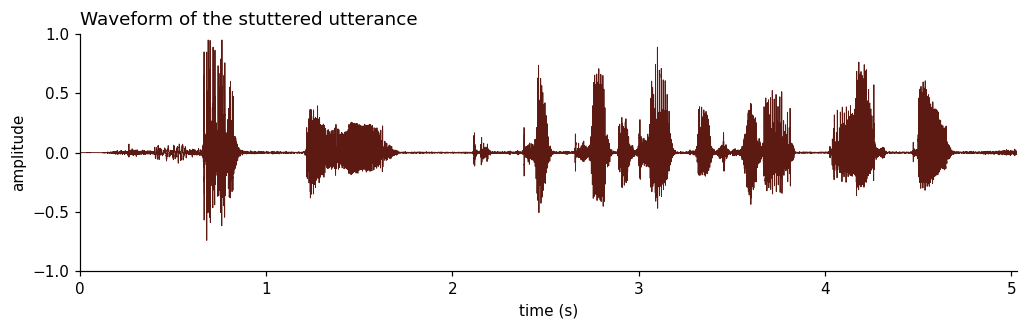

In [ ]:
y, _ = librosa.load(AUDIO_PATH, sr=SR, mono=True)
y = (y / np.max(np.abs(y)) * 0.95).astype(np.float32)
DUR = len(y) / SR
print(f"{AUDIO_PATH.name}\n  duration {DUR:.2f} s | {len(y)} samples at {SR} Hz | peak {np.max(np.abs(y)):.2f}")
sf.write(OUT / "input_16k.wav", y, SR, subtype="PCM_16")
display(Audio(y, rate=SR))

t = np.arange(len(y)) / SR
fig, ax = plt.subplots(figsize=(11, 2.8))
ax.plot(t, y, color=C["floor"], lw=0.6); ax.set_xlim(0, DUR); ax.set_ylim(-1, 1)
ax.set_xlabel("time (s)"); ax.set_ylabel("amplitude"); ax.set_title("Waveform of the stuttered utterance", loc="left")
fig.savefig(OUT / "fig_waveform_plain.png", dpi=200, bbox_inches="tight"); plt.show()

## 2. Feature extraction
Speech is cut into overlapping frames (25 ms window, 10 ms hop = 400 and 160 samples at 16 kHz). For each frame we compute
**MFCCs** (13 coefficients) and **short-time energy / spectral flatness**. The frames then let us find the disfluent
regions without any labels:

* **block**: a silent gap inside speech (≥ 250 ms), or a shorter silence (≥ 150 ms) followed by a sudden burst;
* **prolongation**: a voiced stretch ≥ 300 ms where the MFCC vector hardly changes and the pitch (pYIN) is continuous;
* **repetition**: neighbouring syllable-sized segments (< 400 ms) whose mean MFCC vectors are almost identical (cosine > 0.9).

frames: 504 (10 ms each) | MFCC matrix (13, 504) | voiced frames 240 (48 %)


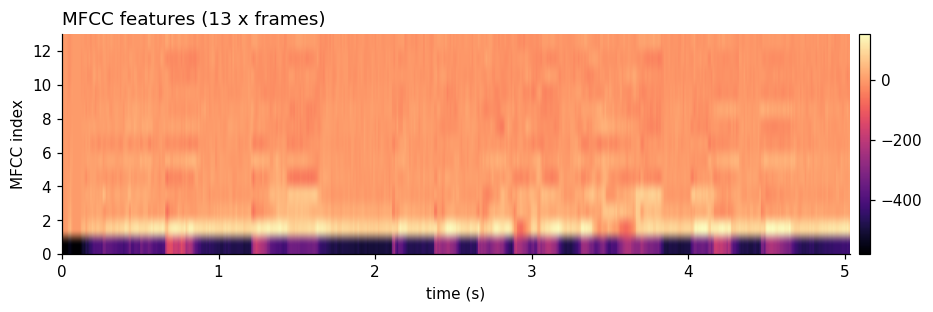

In [ ]:
HOP, WIN = 160, 400
mfcc = librosa.feature.mfcc(y=y, sr=SR, n_mfcc=13, n_fft=WIN, hop_length=HOP, win_length=WIN, n_mels=80)
rms  = librosa.feature.rms(y=y, frame_length=WIN, hop_length=HOP)[0]
flat = librosa.feature.spectral_flatness(y=y, n_fft=WIN, hop_length=HOP, win_length=WIN)[0]
n = min(len(rms), len(flat), mfcc.shape[1]); rms, flat, mfcc = rms[:n], flat[:n], mfcc[:, :n]
thr = max(np.percentile(rms, 90) * 0.12, 1e-4)
voiced = medfilt(((rms > thr) & (flat < 0.5)).astype(np.float32), 5) > 0.5     # voice activity, 10 ms frames
print(f"frames: {n} (10 ms each) | MFCC matrix {mfcc.shape} | voiced frames {voiced.sum()} ({100*voiced.mean():.0f} %)")

fig, ax = plt.subplots(figsize=(11, 2.6))
im = ax.imshow(mfcc, origin="lower", aspect="auto", extent=[0, DUR, 0, 13], cmap="magma")
ax.set_xlabel("time (s)"); ax.set_ylabel("MFCC index"); ax.set_title("MFCC features (13 x frames)", loc="left")
fig.colorbar(im, ax=ax, pad=0.01); fig.savefig(OUT / "fig_mfcc.png", dpi=200, bbox_inches="tight"); plt.show()

 start  end       type  duration_ms
  0.41 0.57 repetition        160.0
  0.86 1.21      block        350.0
  1.68 2.11      block        430.0
  2.20 2.38      block        180.0
  3.84 4.03      block        190.0
  4.30 4.49      block        190.0


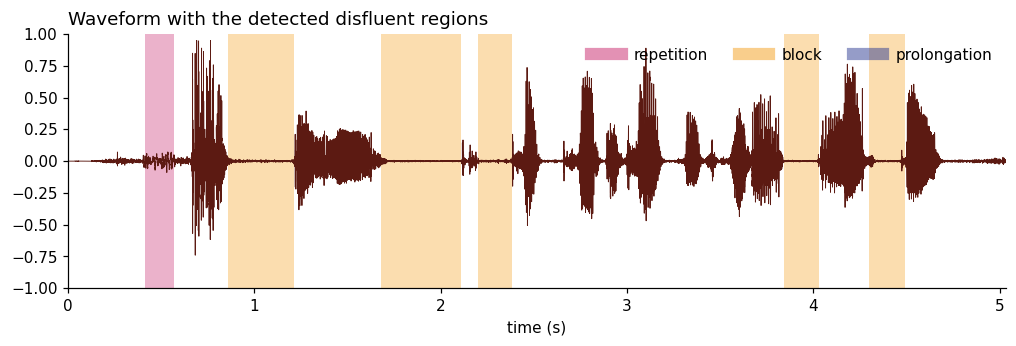

In [ ]:
def runs(mask, value=True):
    out, s = [], None
    for i, m in enumerate(mask):
        if m == value and s is None: s = i
        elif m != value and s is not None: out.append((s, i)); s = None
    if s is not None: out.append((s, len(mask)))
    return out

def detect_blocks():
    v = np.where(voiced)[0]; cands = []
    for a, b in runs(voiced, False):
        if a <= v[0] or b > v[-1]: continue                         # strictly inside speech
        if b - a >= 25: cands.append((a, b, "block"))                # silence >= 250 ms
        elif b - a >= 15 and np.max(rms[b:b + 3]) / (np.mean(rms[a:b]) + 1e-8) > 6:   # silence then burst
            cands.append((a, b, "block"))
    return cands

def detect_prolongations():
    c = mfcc[1:13]; d = np.linalg.norm(np.diff(c, axis=1), axis=0)
    d = np.convolve(np.concatenate([[d[0]], d]) / (np.linalg.norm(c, axis=0) + 1e-6), np.ones(5) / 5, mode="same")
    out = []
    for a, b in runs((d < 0.10) & voiced, True):
        if b - a < 30: continue                                      # >= 300 ms of steady sound
        seg = y[a * HOP: b * HOP + WIN]
        if len(seg) < 1100: continue
        _, flag, _ = librosa.pyin(seg, fmin=65, fmax=450, sr=SR, frame_length=1024, hop_length=HOP)
        if np.mean(flag) >= 0.8: out.append((a, b, "prolongation"))  # continuous F0
    return out

def detect_repetitions():
    env = np.convolve(rms, np.ones(5) / 5, mode="same"); segs = []
    for a, b in runs(voiced, True):                                  # split voiced runs at energy dips
        cuts = [a]
        if b - a > 8:
            e = env[a:b]; dips, _ = find_peaks(-e, prominence=max(0.3 * float(e.max()), 1e-6)); cuts += [a + int(k) for k in dips]
        cuts.append(b); segs += [(s, t) for s, t in zip(cuts[:-1], cuts[1:]) if t - s >= 4]
    f = mfcc[1:13] - mfcc[1:13][:, voiced].mean(axis=1, keepdims=True)
    vec = [f[:, a:b].mean(axis=1) for a, b in segs]
    cos = lambda u, w: float(u @ w / (np.linalg.norm(u) * np.linalg.norm(w) + 1e-9))
    out, i = [], 0
    while i < len(segs) - 1:
        j = i
        while (j + 1 < len(segs) and segs[j][1] - segs[j][0] < 40 and segs[j + 1][1] - segs[j + 1][0] < 40
               and segs[j + 1][0] - segs[j][1] <= 25 and cos(vec[j], vec[j + 1]) > 0.9): j += 1
        if j > i: out.append((segs[i][0], segs[j][1], "repetition"))
        i = j + 1
    return out

cand = sorted(detect_blocks() + detect_prolongations() + detect_repetitions(), key=lambda c: ({"block": 0, "prolongation": 1, "repetition": 2}[c[2]], c[0]))
kept = []
for a, b, k in cand:                                                  # priority block > prolongation > repetition
    if all(b <= ka or a >= kb for ka, kb, _ in kept): kept.append((a, b, k))
REGIONS = [dict(start=round(a * .01, 2), end=round(b * .01, 2), type=k) for a, b, k in sorted(kept)]
print(pd.DataFrame(REGIONS).assign(duration_ms=lambda d: ((d.end - d.start) * 1000).round()).to_string(index=False))

COL = {"repetition": C["magenta"], "block": C["marigold"], "prolongation": C["indigo"]}
fig, ax = plt.subplots(figsize=(11, 3.0))
for r in REGIONS: ax.axvspan(r["start"], r["end"], color=COL[r["type"]], alpha=0.35, lw=0)
ax.plot(t, y, color=C["floor"], lw=0.6); ax.set_xlim(0, DUR); ax.set_ylim(-1, 1)
for k, c in COL.items(): ax.plot([], [], color=c, lw=8, alpha=0.5, label=k)
ax.legend(frameon=False, ncol=3, loc="upper right"); ax.set_xlabel("time (s)")
ax.set_title("Waveform with the detected disfluent regions", loc="left")
fig.savefig(OUT / "fig_waveform.png", dpi=200, bbox_inches="tight"); plt.show()

## 3. Log-Mel spectrum
The magnitude spectrum of every frame is passed through **80 triangular Mel filters** (0 – 8 kHz). The Mel scale spaces the
filters like human hearing: roughly linear below 1 kHz and logarithmic above.

$$m = 2595\,\log_{10}\!\left(1 + \frac{f}{700}\right), \qquad \text{log-Mel} = 10\log_{10}\big(\text{Mel power}\big)\ \text{dB}$$

Silent blocks show up as dark vertical gaps; the stutter is visible as the short, repeated bursts of energy.

log-Mel shape: (80, 504) (80 Mel bands x frames) | range -80 .. 0 dB


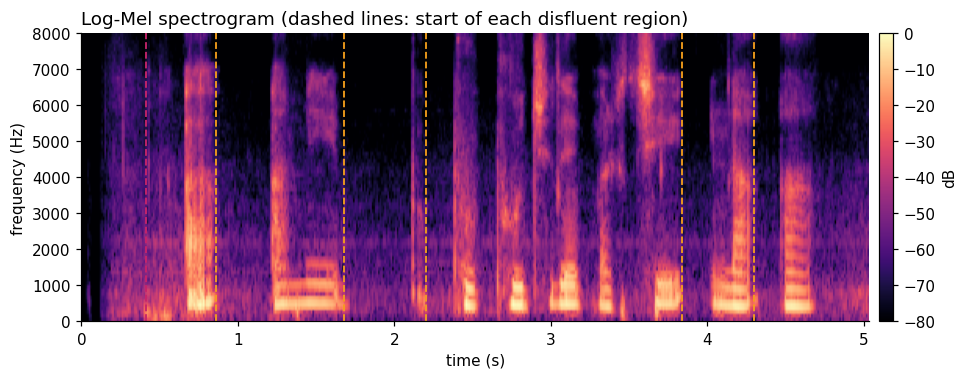

In [ ]:
S = librosa.feature.melspectrogram(y=y, sr=SR, n_fft=WIN, hop_length=HOP, win_length=WIN, n_mels=80, fmin=0, fmax=8000, power=2.0)
logmel = librosa.power_to_db(S, ref=np.max)                    # dB, 0 dB = loudest cell
print("log-Mel shape:", logmel.shape, "(80 Mel bands x frames) | range", f"{logmel.min():.0f} .. {logmel.max():.0f} dB")

fig, ax = plt.subplots(figsize=(11, 3.4))
im = ax.imshow(logmel, origin="lower", aspect="auto", extent=[0, DUR, 0, 8000], cmap="magma", vmin=-80, vmax=0)
for r in REGIONS: ax.axvline(r["start"], color=COL[r["type"]], lw=1.2, ls="--")
ax.set_xlabel("time (s)"); ax.set_ylabel("frequency (Hz)"); ax.set_title("Log-Mel spectrogram (dashed lines: start of each disfluent region)", loc="left")
fig.colorbar(im, ax=ax, pad=0.01, label="dB"); fig.savefig(OUT / "fig_logmel.png", dpi=200, bbox_inches="tight"); plt.show()

## 4. ASR architecture
Two recognisers of different families are compared:

* **wav2vec 2.0 / XLS-R + CTC** (`arijitx/wav2vec2-xls-r-300m-bengali`): a CNN turns the waveform into 20 ms frames, a Transformer
  encoder adds context, a linear layer scores every token per frame, and **CTC** turns the frame scores into text.
* **Whisper small** (`openai/whisper-small`): the log-Mel spectrogram goes through a Transformer encoder; an autoregressive
  Transformer decoder then writes the text token by token (here forced to Bengali, `language="bn"`).

The numbers in the diagram are read from the model configurations.

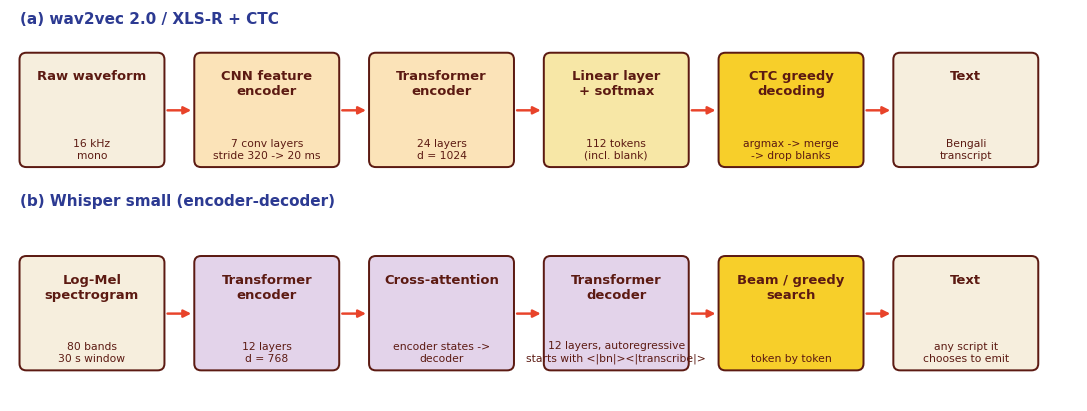

In [ ]:
from transformers import AutoConfig
W2V_ID, WHISPER_ID, TTS_ID = "arijitx/wav2vec2-xls-r-300m-bengali", "openai/whisper-small", "facebook/mms-tts-ben"
cw, cwh = AutoConfig.from_pretrained(W2V_ID), AutoConfig.from_pretrained(WHISPER_ID)

fig, ax = plt.subplots(figsize=(12.5, 4.6)); ax.axis("off"); ax.set_xlim(0, 12.5); ax.set_ylim(0, 4.6)
def box(x, y0, w, h, title, sub="", fc=None):
    ax.add_patch(FancyBboxPatch((x, y0), w, h, boxstyle="round,pad=0,rounding_size=0.08", fc=fc or C["rice"], ec=C["floor"], lw=1.3))
    ax.text(x + w / 2, y0 + h - 0.2, title, ha="center", va="top", fontsize=8.6, fontweight="bold", color=C["floor"])
    ax.text(x + w / 2, y0 + 0.08, sub, ha="center", va="bottom", fontsize=7, color=C["floor"], linespacing=1.3)
def arr(x0, x1, y0): ax.annotate("", xy=(x1, y0), xytext=(x0, y0), arrowprops=dict(arrowstyle="-|>", color=C["vermilion"], lw=1.6))

ax.text(0.1, 4.45, "(a) wav2vec 2.0 / XLS-R + CTC", fontsize=10, fontweight="bold", color=C["indigo"])
row = [("Raw waveform", "16 kHz\nmono", C["rice"]),
       ("CNN feature\nencoder", f"{len(cw.conv_dim)} conv layers\nstride 320 -> 20 ms", "#fbe3b8"),
       ("Transformer\nencoder", f"{cw.num_hidden_layers} layers\nd = {cw.hidden_size}", "#fbe3b8"),
       ("Linear layer\n+ softmax", f"{cw.vocab_size} tokens\n(incl. blank)", "#f7e7a6"),
       ("CTC greedy\ndecoding", "argmax -> merge\n-> drop blanks", C["turmeric"]),
       ("Text", "Bengali\ntranscript", C["rice"])]
for i, (a, b, f) in enumerate(row):
    x = 0.1 + i * 2.05; box(x, 2.75, 1.7, 1.35, a, b, f)
    if i < len(row) - 1: arr(x + 1.7, x + 2.05, 3.42)

ax.text(0.1, 2.3, "(b) Whisper small (encoder-decoder)", fontsize=10, fontweight="bold", color=C["indigo"])
row = [("Log-Mel\nspectrogram", "80 bands\n30 s window", C["rice"]),
       ("Transformer\nencoder", f"{cwh.encoder_layers} layers\nd = {cwh.d_model}", "#e3d3ea"),
       ("Cross-attention", "encoder states ->\ndecoder", "#e3d3ea"),
       ("Transformer\ndecoder", f"{cwh.decoder_layers} layers, autoregressive\nstarts with <|bn|><|transcribe|>", "#e3d3ea"),
       ("Beam / greedy\nsearch", "token by token", C["turmeric"]),
       ("Text", "any script it\nchooses to emit", C["rice"])]
for i, (a, b, f) in enumerate(row):
    x = 0.1 + i * 2.05; box(x, 0.35, 1.7, 1.35, a, b, f)
    if i < len(row) - 1: arr(x + 1.7, x + 2.05, 1.02)
fig.savefig(OUT / "fig_asr_architecture.png", dpi=200, bbox_inches="tight"); plt.show()

## 5. ASR model 1: wav2vec 2.0 + CTC
The model outputs one score vector per 20 ms frame. Softmax turns it into **posteriors** $p_t(k)$ over the 112 tokens
(letters, vowel signs, the word delimiter `|` and the **blank**).

In [ ]:
from transformers import Wav2Vec2ForCTC, Wav2Vec2Processor
t0 = time.perf_counter()
proc = Wav2Vec2Processor.from_pretrained(W2V_ID)
w2v = Wav2Vec2ForCTC.from_pretrained(W2V_ID, torch_dtype=torch.float16 if DEVICE == "cuda" else torch.float32).to(DEVICE).eval()
print(f"loaded in {time.perf_counter() - t0:.1f} s | parameters: {sum(p.numel() for p in w2v.parameters()) / 1e6:.0f} M")

VOCAB = proc.tokenizer.get_vocab(); ID2TOK = {i: t for t, i in VOCAB.items()}
BLANK = proc.tokenizer.pad_token_id                                     # the CTC blank is the <pad> token
print("vocabulary:", len(VOCAB), "tokens | blank id:", BLANK, "| word delimiter: '|'")

def w2v_logits(wave):
    inp = proc(wave, sampling_rate=SR, return_tensors="pt").input_values.to(DEVICE, dtype=w2v.dtype)
    with torch.inference_mode(): return w2v(inp).logits[0].float().cpu()

w2v_logits(np.zeros(SR, dtype=np.float32))                              # warm-up (excluded from the latency)
t0 = time.perf_counter(); logits = w2v_logits(y); LAT_W2V = time.perf_counter() - t0
post = torch.softmax(logits, dim=-1).numpy()                             # [T, V] posteriors
T = post.shape[0]
print(f"logits {tuple(logits.shape)} -> {T} frames of {DUR / T * 1000:.0f} ms | inference {LAT_W2V:.2f} s")

loaded in 2.1 s | parameters: 316 M
vocabulary: 112 tokens | blank id: 109 | word delimiter: '|'


logits (251, 112) -> 251 frames of 20 ms | inference 1.03 s


## 6. CTC: how frame scores become text
CTC lets the network emit one label per frame **without knowing the alignment**. A special **blank** symbol means "no new
label here". A frame sequence $\pi$ is turned into text by the many-to-one map $\mathcal{B}$:

1. **merge** consecutive repeats, 2. **remove** blanks.

$$P(Y\mid X)=\sum_{\pi\in\mathcal{B}^{-1}(Y)}\ \prod_{t=1}^{T} p_t(\pi_t)\qquad\qquad \mathcal{B}(\text{<blk>}\,a\,a\,\text{<blk>}\,m\,i)=\text{ami}$$

Training maximises this sum with dynamic programming; at inference we use the **greedy path** $\hat\pi_t=\arg\max_k p_t(k)$.

*Why this matters for stuttering:* a repeated sound that the model hears as two separate events, with a blank (or a gap)
between them, stays **two** tokens after collapsing, so the stutter appears in the text as an extra token (an *insertion*).
A sound held across many frames merges into one token.

In [ ]:
def collapse(frames, blank="<blk>"):
    merged = [f for i, f in enumerate(frames) if i == 0 or f != frames[i - 1]]
    no_blank = [f for f in merged if f != blank]
    text = " ".join("".join(" " if f == "|" else f for f in no_blank).split())
    return merged, no_blank, text

# the toy example from the formula above
raw_toy = ["<blk>", "আ", "আ", "<blk>", "ম", "ি"]
print("toy  raw     :", raw_toy)
print("toy  merged  :", collapse(raw_toy)[0]); print("toy  no blank:", collapse(raw_toy)[1], "->", collapse(raw_toy)[2])

# the real utterance
ids = post.argmax(axis=-1)
frames = ["<blk>" if i == BLANK else ID2TOK[int(i)] for i in ids]
merged, no_blank, W2V_TEXT = collapse(frames)
blank_frac = float(np.mean(ids == BLANK))
print(f"\nreal raw frames    : {len(frames)} ({100 * blank_frac:.0f} % blank)")
print(f"after merging      : {len(merged)}")
print(f"after removing <blk>: {len(no_blank)} tokens -> {no_blank}")
print("decoded text       :", W2V_TEXT)

nz = [(round(k * DUR / T, 2), frames[k], round(float(post[k, ids[k]]), 2)) for k in range(T) if ids[k] != BLANK]
display(pd.DataFrame(nz, columns=["time (s)", "token", "posterior"]).T)

toy  raw     : ['<blk>', 'আ', 'আ', '<blk>', 'ম', 'ি']
toy  merged  : ['<blk>', 'আ', '<blk>', 'ম', 'ি']
toy  no blank: ['আ', 'ম', 'ি'] -> আমি

real raw frames    : 251 (91 % blank)
after merging      : 41
after removing <blk>: 21 tokens -> ['আ', 'ম', 'ি', '|', 'ভ', 'ু', 'ঝ', 'ত', 'ে', '|', 'প', 'া', 'র', 'ছ', 'ি', '|', 'ন', 'া', '|', 'আ', '|']
decoded text       : আমি ভুঝতে পারছি না আ


,0,1,2,3,4,5,6,7,8,9,...,12,13,14,15,16,17,18,19,20,21
time (s),0.92,1.36,1.5,1.64,2.55,2.77,2.89,3.03,3.11,3.19,...,3.33,3.41,3.53,3.73,3.85,4.05,4.23,4.31,4.35,5.01
token,আ,ম,ি,|,ভ,ু,ঝ,ত,ে,|,...,া,র,ছ,ি,|,ন,া,|,আ,|
posterior,1.0,1.0,1.0,0.99,0.36,0.99,0.64,0.98,1.0,0.99,...,0.71,0.97,1.0,1.0,0.99,1.0,1.0,0.92,0.94,1.0


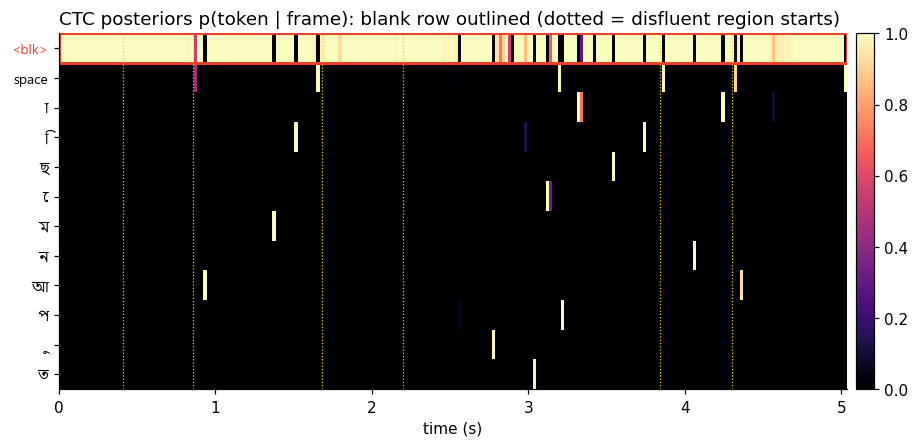

In [ ]:
top = [BLANK] + [k for k in np.argsort(-np.array([post[:, k].max() if k != BLANK else -1 for k in range(post.shape[1])]))[:11]]
names = ["<blk>"] + [("space" if ID2TOK[k] == "|" else ID2TOK[k]) for k in top[1:]]
fig, ax = plt.subplots(figsize=(11, 4.2))
im = ax.imshow(post[:, top].T, aspect="auto", cmap="magma", vmin=0, vmax=1, extent=[0, DUR, len(top), 0])
ax.set_yticks(np.arange(len(top)) + 0.5); ax.set_yticklabels(names, fontproperties=bn(9))
ax.get_yticklabels()[0].set_color(C["vermilion"]); ax.add_patch(plt.Rectangle((0, 0), DUR, 1, fill=False, ec=C["vermilion"], lw=2))
for r in REGIONS: ax.axvline(r["start"], color=C["turmeric"], lw=0.8, ls=":")
ax.set_xlabel("time (s)"); ax.set_title("CTC posteriors p(token | frame): blank row outlined (dotted = disfluent region starts)", loc="left")
fig.colorbar(im, ax=ax, pad=0.01); fig.savefig(OUT / "fig_ctc_posteriors.png", dpi=200, bbox_inches="tight"); plt.show()

## 7. ASR model 2: Whisper small (language forced to Bengali)

In [ ]:
from transformers import pipeline
t0 = time.perf_counter()
whisper = pipeline("automatic-speech-recognition", model=WHISPER_ID, device=0 if DEVICE == "cuda" else -1,
                   torch_dtype=torch.float16 if DEVICE == "cuda" else torch.float32)
print(f"loaded in {time.perf_counter() - t0:.1f} s | parameters: {sum(p.numel() for p in whisper.model.parameters()) / 1e6:.0f} M")
GEN = {"language": "bn", "task": "transcribe"}
whisper({"raw": y[:SR], "sampling_rate": SR}, generate_kwargs={**GEN, "max_new_tokens": 8})       # short warm-up (excluded from the latency)
t0 = time.perf_counter()
WHISPER_TEXT = whisper({"raw": y, "sampling_rate": SR}, chunk_length_s=30, generate_kwargs=GEN)["text"].strip()
LAT_WHISPER = time.perf_counter() - t0
print("Whisper output:", WHISPER_TEXT, f"\ninference {LAT_WHISPER:.2f} s")
print("contains Bengali letters:", bool(re.search("[ঀ-৿]", WHISPER_TEXT)))

loaded in 1.2 s | parameters: 242 M


Whisper output: आ, आमे पुछ दे पर ची ना आ 
inference 4.11 s
contains Bengali letters: False


## 8. Text and WER calculation
Both outputs are normalised (Unicode NFC, punctuation and the danda removed) and compared with the reference word by word.
The edit distance gives the number of **substitutions S, deletions D and insertions I**:

$$\mathrm{WER}=\frac{S+D+I}{N},\qquad \mathrm{CER}=\frac{S_c+D_c+I_c}{N_c}$$

where $N$ is the number of reference words ($N_c$ characters). WER can exceed 100 % because insertions are counted.
Below the alignment is computed **by hand** (dynamic programming) and then cross-checked against `jiwer`.

In [ ]:
def normalise(txt):
    txt = unicodedata.normalize("NFC", txt)
    txt = re.sub(r"[​﻿‎‏⁠]", "", txt)
    txt = re.sub(r"[।॥,?!.;:\"'“”‘’()\[\]{}…–—]", " ", txt)
    return " ".join(txt.split())

def align(ref, hyp):                                   # Levenshtein table + back-trace
    n, m = len(ref), len(hyp); D = np.zeros((n + 1, m + 1), int); D[:, 0] = range(n + 1); D[0, :] = range(m + 1)
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            D[i, j] = min(D[i - 1, j - 1] + (ref[i - 1] != hyp[j - 1]), D[i - 1, j] + 1, D[i, j - 1] + 1)
    i, j, ops = n, m, []
    while i > 0 or j > 0:
        if i > 0 and j > 0 and D[i, j] == D[i - 1, j - 1] + (ref[i - 1] != hyp[j - 1]):
            ops.append(("correct" if ref[i - 1] == hyp[j - 1] else "substitution", ref[i - 1], hyp[j - 1])); i -= 1; j -= 1
        elif i > 0 and D[i, j] == D[i - 1, j] + 1: ops.append(("deletion", ref[i - 1], "-")); i -= 1
        else: ops.append(("insertion", "-", hyp[j - 1])); j -= 1
    return ops[::-1], int(D[n, m])

REF_N = normalise(REFERENCE); ref_words = REF_N.split()
RESULTS = {}
for name, raw in [("wav2vec2 + CTC", W2V_TEXT), ("Whisper small", WHISPER_TEXT)]:
    hyp_n = normalise(raw); ops, dist = align(ref_words, hyp_n.split())
    o = jiwer.process_words(REF_N, hyp_n)
    S, Dl, I = o.substitutions, o.deletions, o.insertions; N = len(ref_words)
    wer, cer = (S + Dl + I) / N, jiwer.cer(REF_N, hyp_n)
    assert dist == S + Dl + I and abs(wer - o.wer) < 1e-9, "hand-computed distance must equal jiwer"
    RESULTS[name] = dict(text=raw, norm=hyp_n, S=S, D=Dl, I=I, N=N, wer=wer, cer=cer, ops=ops)
    print(f"\n=== {name} ===\nreference : {REF_N}\nhypothesis: {hyp_n}")
    display(pd.DataFrame(ops, columns=["operation", "reference word", "hypothesis word"]))
    print(f"S = {S}, D = {Dl}, I = {I}, N = {N}   ->   WER = ({S} + {Dl} + {I}) / {N} = {100 * wer:.1f} %   |   CER = {100 * cer:.1f} %")


=== wav2vec2 + CTC ===
reference : আমি বুঝতে পারছি না
hypothesis: আমি ভুঝতে পারছি না আ


,operation,reference word,hypothesis word
0,correct,আমি,আমি
1,substitution,বুঝতে,ভুঝতে
2,correct,পারছি,পারছি
3,correct,না,না
4,insertion,-,আ


S = 1, D = 0, I = 1, N = 4   ->   WER = (1 + 0 + 1) / 4 = 50.0 %   |   CER = 16.7 %

=== Whisper small ===
reference : আমি বুঝতে পারছি না
hypothesis: आ आमे पुछ दे पर ची ना आ


,operation,reference word,hypothesis word
0,insertion,-,आ
1,insertion,-,आमे
2,insertion,-,पुछ
3,insertion,-,दे
4,substitution,আমি,पर
5,substitution,বুঝতে,ची
6,substitution,পারছি,ना
7,substitution,না,आ


S = 4, D = 0, I = 4, N = 4   ->   WER = (4 + 0 + 4) / 4 = 200.0 %   |   CER = 111.1 %


## 9. ASR comparison table

In [ ]:
rows = []
for name, arch, params, dec, lat in [
        ("wav2vec2 + CTC", "XLS-R encoder + CTC head", sum(p.numel() for p in w2v.parameters()) / 1e6, "greedy CTC", LAT_W2V),
        ("Whisper small", "encoder-decoder Transformer", sum(p.numel() for p in whisper.model.parameters()) / 1e6, "autoregressive", LAT_WHISPER)]:
    r = RESULTS[name]
    rows.append({"Model": name, "Architecture": arch, "Params (M)": round(params), "Decoding": dec, "Output": r["text"],
                 "Bengali script": "yes" if re.search("[ঀ-৿]", r["text"]) else "no",
                 "S": r["S"], "D": r["D"], "I": r["I"], "WER %": round(100 * r["wer"], 1), "CER %": round(100 * r["cer"], 1),
                 "Latency (s)": round(lat, 2)})
CMP = pd.DataFrame(rows); CMP.to_csv(OUT / "asr_comparison.csv", index=False, encoding="utf-8-sig")
display(CMP)
BEST = CMP.sort_values(["WER %", "CER %"]).iloc[0]["Model"]
print("lowest WER:", BEST)

,Model,Architecture,Params (M),Decoding,Output,Bengali script,S,D,I,WER %,CER %,Latency (s)
0,wav2vec2 + CTC,XLS-R encoder + CTC head,316,greedy CTC,আমি ভুঝতে পারছি না আ,yes,1,0,1,50.0,16.7,1.03
1,Whisper small,encoder-decoder Transformer,242,autoregressive,"आ, आमे पुछ दे पर ची ना आ",no,4,0,4,200.0,111.1,4.11


lowest WER: wav2vec2 + CTC


## 10. Text to speech: back to a voice
The transcript of the best model (lowest WER) is cleaned of hyphenated stutter repeats and synthesised with
**MMS-TTS Bengali** (`facebook/mms-tts-ben`, a VITS model). As a closing-the-loop check, the synthesised speech is fed
back into the wav2vec 2.0 recogniser: if the voice is intelligible, it should recover the text it was given.

text sent to TTS: আমি ভুঝতে পারছি না আ


synthesised 1.54 s at 16000 Hz in 0.48 s -> assets/tts_output.wav


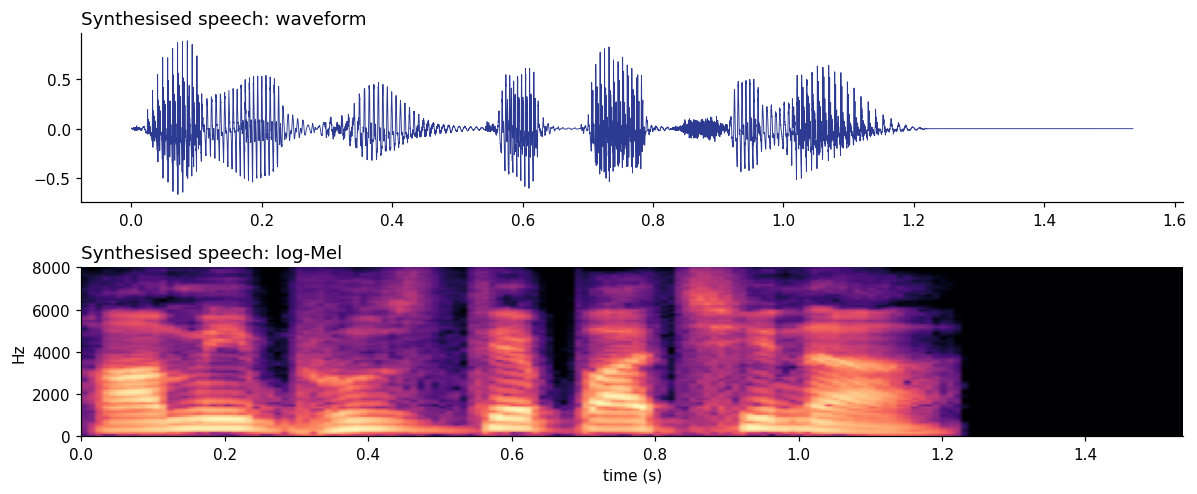

In [ ]:
from transformers import VitsModel, AutoTokenizer
def drop_stutter_repeats(txt):                          # "আ-আ-আমি" -> "আমি" (all parts but the last are prefixes of the last)
    out = []
    for w in txt.split():
        parts = w.split("-")
        out.append(parts[-1] if len(parts) > 1 and all(p and parts[-1].startswith(p) for p in parts[:-1]) else w)
    return " ".join(out)
spoken = normalise(drop_stutter_repeats(RESULTS[BEST]["text"]))
print("text sent to TTS:", spoken)

tok = AutoTokenizer.from_pretrained(TTS_ID); tts = VitsModel.from_pretrained(TTS_ID).to(DEVICE).eval()
assert not getattr(tok, "is_uroman", False), "this checkpoint would need romanised input"
ids_tts = tok(spoken, return_tensors="pt")
assert ids_tts["input_ids"].numel() > 0, "the TTS vocabulary has no characters for this text (is it Bengali script?)"
t0 = time.perf_counter()
torch.manual_seed(0)                                    # VITS is stochastic: fix the seed so the output is reproducible
with torch.inference_mode(): wav = tts(**{k: v.to(DEVICE) for k, v in ids_tts.items()}).waveform[0].float().cpu().numpy()
LAT_TTS = time.perf_counter() - t0
TTS_SR = tts.config.sampling_rate
sf.write(OUT / "tts_output.wav", wav, TTS_SR, subtype="PCM_16")
print(f"synthesised {len(wav) / TTS_SR:.2f} s at {TTS_SR} Hz in {LAT_TTS:.2f} s -> assets/tts_output.wav")
display(Audio(wav, rate=TTS_SR))

wav16 = librosa.resample(wav, orig_sr=TTS_SR, target_sr=SR) if TTS_SR != SR else wav
Sg = librosa.power_to_db(librosa.feature.melspectrogram(y=wav16, sr=SR, n_fft=WIN, hop_length=HOP, win_length=WIN, n_mels=80, fmin=0, fmax=8000), ref=np.max)
fig, axs = plt.subplots(2, 1, figsize=(11, 4.6), sharex=False)
axs[0].plot(np.arange(len(wav16)) / SR, wav16, color=C["indigo"], lw=0.6); axs[0].set_title("Synthesised speech: waveform", loc="left")
axs[1].imshow(Sg, origin="lower", aspect="auto", extent=[0, len(wav16) / SR, 0, 8000], cmap="magma", vmin=-80, vmax=0)
axs[1].set_xlabel("time (s)"); axs[1].set_ylabel("Hz"); axs[1].set_title("Synthesised speech: log-Mel", loc="left")
fig.tight_layout(); fig.savefig(OUT / "fig_tts.png", dpi=200, bbox_inches="tight"); plt.show()

In [ ]:
# round trip: synthesised speech -> wav2vec2 -> text
rt_logits = w2v_logits((wav16 / np.max(np.abs(wav16)) * 0.95).astype(np.float32))
rt_ids = rt_logits.argmax(-1).numpy(); rt_text = collapse(["<blk>" if i == BLANK else ID2TOK[int(i)] for i in rt_ids])[2]
rt_wer_spoken = jiwer.wer(normalise(spoken), normalise(rt_text)) if normalise(rt_text) else 1.0
rt_wer_ref = jiwer.wer(REF_N, normalise(rt_text)) if normalise(rt_text) else 1.0
print("text given to TTS      :", spoken)
print("recognised from the TTS:", rt_text)
print(f"round-trip WER vs the text it was given: {100 * rt_wer_spoken:.1f} %   |   vs the original reference: {100 * rt_wer_ref:.1f} %")

text given to TTS      : আমি ভুঝতে পারছি না আ
recognised from the TTS: আমি ভুঝতে পারছি না
round-trip WER vs the text it was given: 20.0 %   |   vs the original reference: 25.0 %


## 11. Summary and saved results

In [ ]:
counts = {k: sum(1 for r in REGIONS if r["type"] == k) for k in ("repetition", "block", "prolongation")}
results = {
  "audio_file": AUDIO_PATH.name, "duration_s": round(DUR, 2), "sample_rate": SR, "reference": REFERENCE, "device": DEVICE,
  "frames_10ms": int(n), "voiced_percent": round(100 * float(voiced.mean())),
  "regions": REGIONS, "region_counts": counts,
  "logmel_shape": list(logmel.shape), "mfcc_shape": list(mfcc.shape),
  "ctc": {"frames": int(T), "frame_ms": round(DUR / T * 1000, 1), "blank_percent": round(100 * blank_frac),
          "merged": len(merged), "tokens": len(no_blank), "vocab_size": len(VOCAB)},
  "models": {k: {kk: (round(vv, 4) if isinstance(vv, float) else vv) for kk, vv in v.items() if kk != "ops"} for k, v in RESULTS.items()},
  "alignment": {k: [list(o) for o in v["ops"]] for k, v in RESULTS.items()},
  "ctc_nonblank_frames": [[float(a), b, float(c)] for a, b, c in nz], "ctc_tokens": no_blank, "ctc_decoded": W2V_TEXT,
  "comparison": json.loads(CMP.to_json(orient="records", force_ascii=False)),
  "latency_s": {"wav2vec2": round(LAT_W2V, 3), "whisper": round(LAT_WHISPER, 3), "tts": round(LAT_TTS, 3)},
  "best_model": BEST, "tts": {"text": spoken, "seconds": round(len(wav) / TTS_SR, 2), "sample_rate": TTS_SR,
          "roundtrip_text": rt_text, "roundtrip_wer_vs_spoken": round(rt_wer_spoken, 4), "roundtrip_wer_vs_reference": round(rt_wer_ref, 4)},
  "versions": {"torch": torch.__version__, "python": sys.version.split()[0]},
}
import transformers; results["versions"]["transformers"] = transformers.__version__
(OUT.parent / "results.json").write_text(json.dumps(results, ensure_ascii=False, indent=1), encoding="utf-8")
print(json.dumps({k: results[k] for k in ("duration_s", "region_counts", "best_model")}, ensure_ascii=False))
print(f"\nwav2vec2 + CTC : WER {100 * RESULTS['wav2vec2 + CTC']['wer']:.1f} %   (S={RESULTS['wav2vec2 + CTC']['S']} D={RESULTS['wav2vec2 + CTC']['D']} I={RESULTS['wav2vec2 + CTC']['I']})")
print(f"Whisper small  : WER {100 * RESULTS['Whisper small']['wer']:.1f} %   (S={RESULTS['Whisper small']['S']} D={RESULTS['Whisper small']['D']} I={RESULTS['Whisper small']['I']})")
print("saved: results.json, assets/*.png, assets/asr_comparison.csv, assets/tts_output.wav")

{"duration_s": 5.03, "region_counts": {"repetition": 1, "block": 5, "prolongation": 0}, "best_model": "wav2vec2 + CTC"}

wav2vec2 + CTC : WER 50.0 %   (S=1 D=0 I=1)
Whisper small  : WER 200.0 %   (S=4 D=0 I=4)
saved: results.json, assets/*.png, assets/asr_comparison.csv, assets/tts_output.wav


### Conclusions
* The detector finds the disfluent regions from the signal alone; the log-Mel spectrogram shows them as silent gaps and bursts.
* The CTC model outputs Bengali but **inserts a spurious token** where the stutter sits and **substitutes** a letter inside a word;
  CTC cannot "skip" a sound it believes it heard.
* Whisper small forced to Bengali never wrote Bengali script on this clip, so every word counts as an error.
* TTS speaks whatever the recogniser wrote, so recognition errors are repeated in the output voice.

*Limits:* one clip, one speaker, a reference typed by the speaker; the numbers show the behaviour of the pipeline, not the
accuracy of the models in general.